# 07 – Literature Context and Comparability Audit

This notebook reproduces the descriptive fraction of represented stars in the filtered Kepler KOI catalog that have at least one confirmed entry. It then provides a checklist for auditing published occurrence-rate estimates.

**Important:** This catalog fraction is not an occurrence rate among all Kepler target stars. Published rates may use different target populations, planet-radius and period ranges, denominators, completeness corrections, transit-probability corrections, and false-positive treatments. Do not compare values numerically unless their definitions are demonstrably compatible.

## 1. Load the Kepler catalog

In [6]:
import os, csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "/kaggle/input/datasets/sairakeshnagaram/koi-dataset/cumulative_2026.10.20_19.25.07.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}. Attach the KOI dataset and update DATA_PATH.")

header_row = None
with open(DATA_PATH, "r", encoding="utf-8-sig", errors="replace", newline="") as f:
    for i, line in enumerate(f):
        try:
            names = [x.strip().lower() for x in next(csv.reader([line]))]
        except Exception:
            continue
        if "kepid" in names and "koi_disposition" in names:
            header_row = i
            break
if header_row is None:
    raise ValueError("Could not find the CSV header containing kepid and koi_disposition.")

raw = pd.read_csv(DATA_PATH, skiprows=header_row, engine="python")
print("Raw shape:", raw.shape)
display(raw.head())

Raw shape: (9564, 49)


,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,10811496,K00753.01,NaN,CANDIDATE,CANDIDATE,0.000,0,0,0,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


## 2. Reproduce the descriptive catalog statistic

In [7]:
required = ["kepid", "koi_disposition", "koi_prad", "koi_steff"]
missing = [c for c in required if c not in raw.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

df = raw.copy()
for col in ["kepid", "koi_prad", "koi_steff"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["koi_disposition"] = df["koi_disposition"].astype(str).str.strip().str.upper()

filtered = df[
    df["kepid"].notna()
    & df["koi_prad"].between(1, 4, inclusive="both")
    & df["koi_steff"].between(4700, 6500, inclusive="both")
].copy()

resolved = filtered[filtered["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])].copy()
n_catalog_stars = int(filtered["kepid"].nunique())
n_confirmed_hosts = int(
    resolved.loc[resolved["koi_disposition"] == "CONFIRMED", "kepid"].nunique()
)
n_resolved_stars = int(resolved["kepid"].nunique())
catalog_fraction = n_confirmed_hosts / n_catalog_stars if n_catalog_stars else np.nan

summary = pd.DataFrame([
    ["Filtered catalog rows (including candidates)", len(filtered)],
    ["Unique stars represented in filtered catalog", n_catalog_stars],
    ["Resolved rows (confirmed + false positive)", len(resolved)],
    ["Unique stars represented among resolved rows", n_resolved_stars],
    ["Unique stars with at least one confirmed entry", n_confirmed_hosts],
    ["Descriptive confirmed-host catalog fraction", catalog_fraction]
], columns=["Quantity", "Value"])

display(summary)
print(f"Descriptive catalog fraction = {catalog_fraction:.4%}")
print("This is NOT an occurrence rate among all Kepler target stars.")

,Quantity,Value
0,Filtered catalog rows (including candidates),4249.00000
1,Unique stars represented in filtered catalog,3517.00000
2,Resolved rows (confirmed + false positive),3195.00000
3,Unique stars represented among resolved rows,2654.00000
4,Unique stars with at least one confirmed entry,1463.00000
5,Descriptive confirmed-host catalog fraction,0.41598


Descriptive catalog fraction = 41.5980%
This is NOT an occurrence rate among all Kepler target stars.


## 3. Literature comparison checklist

Before comparing a published result numerically, verify all of these from the original paper:

- Target-star population / stellar temperature range.
- Planet-radius range.
- Orbital-period range.
- Denominator definition (all target stars, selected stars, or catalog hosts).
- Detection-completeness correction.
- Geometric transit-probability correction.
- Candidate reliability / false-positive treatment.
- Reported quantity and units (planets per star vs. fraction of stars with planets).

The catalog statistic above is conditional on stars represented in the filtered KOI catalog. It does not use the full Kepler target-star denominator or the standard occurrence-rate corrections.

## 4. Enter verified published results (optional)

Only add values copied from original papers. Do not guess or use values from secondary summaries without checking the source. Use `True`, `False`, or `None` for each match/correction field. The comparison checker is intentionally conservative.

In [8]:
literature_records = [
    {
        "paper": "Howard et al. (2012)",
        "citation": "Howard et al. 2012, ApJS, 201, 15 (arXiv:1103.2541)",
        "reported_value": 0.130,
        "value_unit": "planets per star",
        "target_population_match": True,
        "radius_range_match": False,
        "period_range_match": False,
        "denominator_match": False,
        "completeness_corrected": True,
        "transit_probability_corrected": True,
        "reliability_treatment_match": True
    },
    {
        "paper": "Silburt et al. / reconstruction (2014)",
        "citation": "arXiv:1406.6048 (solar-type stars, 1-4 R_earth)",
        "reported_value": 0.46,
        "value_unit": "planets per star",
        "target_population_match": True,
        "radius_range_match": True,
        "period_range_match": False,
        "denominator_match": False,
        "completeness_corrected": True,
        "transit_probability_corrected": True,
        "reliability_treatment_match": True
    },
    {
        "paper": "Kunimoto & Matthews (2020)",
        "citation": "Kunimoto & Matthews 2020, AJ, 159, 248",
        "reported_value": 0.252,
        "value_unit": "planets per star",
        "target_population_match": True,
        "radius_range_match": False,
        "period_range_match": False,
        "denominator_match": False,
        "completeness_corrected": True,
        "transit_probability_corrected": True,
        "reliability_treatment_match": True
    },
    {
        "paper": "Dattilo et al. (2023)",
        "citation": "Dattilo, Batalha & Bryson 2023, AJ",
        "reported_value": 1.52,
        "value_unit": "planets per star",
        "target_population_match": True,
        "radius_range_match": False,
        "period_range_match": False,
        "denominator_match": False,
        "completeness_corrected": True,
        "transit_probability_corrected": True,
        "reliability_treatment_match": True
    }
]

# Convert list → DataFrame (this was missing)
literature = pd.DataFrame(literature_records)
print("Literature records loaded:", len(literature))
display(literature)

Literature records loaded: 4


,paper,citation,reported_value,value_unit,target_population_match,radius_range_match,period_range_match,denominator_match,completeness_corrected,transit_probability_corrected,reliability_treatment_match
0,Howard et al. (2012),"Howard et al. 2012, ApJS, 201, 15 (arXiv:1103....",0.130,planets per star,True,False,False,False,True,True,True
1,Silburt et al. / reconstruction (2014),"arXiv:1406.6048 (solar-type stars, 1-4 R_earth)",0.460,planets per star,True,True,False,False,True,True,True
2,Kunimoto & Matthews (2020),"Kunimoto & Matthews 2020, AJ, 159, 248",0.252,planets per star,True,False,False,False,True,True,True
3,Dattilo et al. (2023),"Dattilo, Batalha & Bryson 2023, AJ",1.520,planets per star,True,False,False,False,True,True,True


## 5. Audit comparability

In [9]:
check_fields = [
    "target_population_match", "radius_range_match", "period_range_match",
    "denominator_match", "completeness_corrected",
    "transit_probability_corrected", "reliability_treatment_match"
]

if literature.empty:
    print("Audit skipped: no literature records.")
else:
    audit_rows = []
    for _, row in literature.iterrows():
        # A field passes only if it is exactly True
        blocked = [c for c in check_fields if row[c] is not True]
        passed = len(blocked) == 0
        audit_rows.append({
            "paper": row["paper"],
            "citation": row["citation"],
            "reported_value": row["reported_value"],
            "value_unit": row["value_unit"],
            "comparable_under_checklist": passed,
            "blocked_reasons": "; ".join(blocked) if blocked else "—"
        })

    audit = pd.DataFrame(audit_rows)
    display(audit)

    if not audit["comparable_under_checklist"].any():
        print("\nNo literature estimate passed all checklist items.")
        print("A direct numerical comparison with the catalog fraction is not justified.")
        print(f"Your descriptive catalog fraction = {catalog_fraction:.4f} "
              f"(conditional on filtered KOI hosts, not a true occurrence rate).")
    else:
        eligible = audit[audit["comparable_under_checklist"]].copy()
        print("Eligible papers for numerical comparison:")
        display(eligible)

,paper,citation,reported_value,value_unit,comparable_under_checklist,blocked_reasons
0,Howard et al. (2012),"Howard et al. 2012, ApJS, 201, 15 (arXiv:1103....",0.130,planets per star,False,radius_range_match; period_range_match; denomi...
1,Silburt et al. / reconstruction (2014),"arXiv:1406.6048 (solar-type stars, 1-4 R_earth)",0.460,planets per star,False,period_range_match; denominator_match
2,Kunimoto & Matthews (2020),"Kunimoto & Matthews 2020, AJ, 159, 248",0.252,planets per star,False,radius_range_match; period_range_match; denomi...
3,Dattilo et al. (2023),"Dattilo, Batalha & Bryson 2023, AJ",1.520,planets per star,False,radius_range_match; period_range_match; denomi...



No literature estimate passed all checklist items.
A direct numerical comparison with the catalog fraction is not justified.
Your descriptive catalog fraction = 0.4160 (conditional on filtered KOI hosts, not a true occurrence rate).


## 6. Plot the catalog statistic (not a literature comparison)

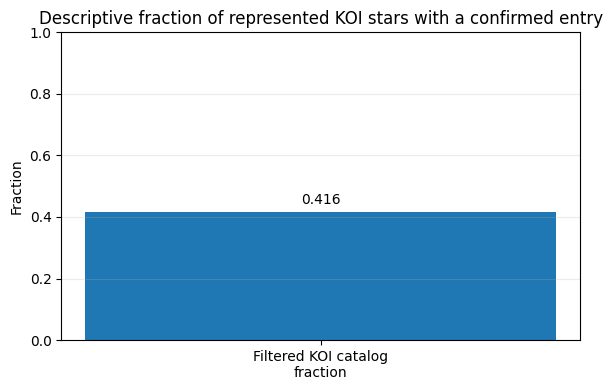

In [10]:
plt.figure(figsize=(6, 4))
plt.bar(["Filtered KOI catalog\nfraction"], [catalog_fraction])
plt.ylim(0, 1)
plt.ylabel("Fraction")
plt.title("Descriptive fraction of represented KOI stars with a confirmed entry")
plt.text(0, catalog_fraction + 0.025, f"{catalog_fraction:.3f}", ha="center")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Suggested scientific wording

> The filtered KOI catalog yielded a descriptive fraction of represented host stars with at least one confirmed entry. This statistic is conditional on inclusion in the filtered KOI catalog and is not equivalent to the occurrence rate among the full Kepler target-star population. Published occurrence-rate estimates were therefore treated as contextual references rather than direct numerical benchmarks unless their target population, planet parameter ranges, denominator, and correction procedures could be demonstrated to match.

A defensible occurrence-rate analysis requires a defined parent target-star sample and appropriate treatment of detection completeness, geometric transit probability, and candidate reliability.

## 8. Save results

In [11]:
OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)
summary.to_csv(os.path.join(OUTPUT_DIR, "07_catalog_fraction_summary.csv"), index=False)
print("Saved:", os.path.join(OUTPUT_DIR, "07_catalog_fraction_summary.csv"))

if not literature.empty:
    literature.to_csv(os.path.join(OUTPUT_DIR, "07_literature_comparison_inputs.csv"), index=False)
    if "audit" in globals():
        audit.to_csv(os.path.join(OUTPUT_DIR, "07_literature_comparability_audit.csv"), index=False)
        print("Saved literature input and comparability audit tables.")

Saved: /kaggle/working/07_catalog_fraction_summary.csv
Saved literature input and comparability audit tables.
